In [1]:
# Cell 1: Import Required Libraries

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Cell 2: Locate the International Dataset

DATA_DIR = r"E:\india-aviation-traffic-main\aggregated\international"

if os.path.exists(DATA_DIR):
    print("International dataset folder found!")

    csv_files = [
        file for file in os.listdir(DATA_DIR)
        if file.lower().endswith(".csv")
    ]

    print("Available CSV files:")
    for file in csv_files:
        print(file)
else:
    print("Folder not found. Please check the path.")

International dataset folder found!
Available CSV files:
carrier.csv
carrier_quarterly.csv
city.csv
country.csv


In [5]:
# Cell 3: Load the Country-Level Aviation Dataset

DATA_PATH = os.path.join(DATA_DIR, "country.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head(10))

Dataset loaded successfully!
Number of rows: 2544
Number of columns: 7


,Year,Quarter,Country,PaxToIndia,PaxFromIndia,FreightToIndia,FreightFromIndia
0,15,1,AFGHANISTAN,37194,32721,96.72,676.42
1,15,2,AFGHANISTAN,26708,30315,118.03,507.01
2,15,3,AFGHANISTAN,27081,20488,103.26,520.70
3,15,4,AFGHANISTAN,24290,18712,276.15,755.51
4,16,1,AFGHANISTAN,39719,38601,200.33,1409.55
5,16,2,AFGHANISTAN,22483,27131,208.44,1166.18
6,16,3,AFGHANISTAN,28759,24894,327.74,1307.04
7,16,4,AFGHANISTAN,37827,32386,284.58,1440.70
8,17,1,AFGHANISTAN,45563,43380,342.48,1244.15
9,17,2,AFGHANISTAN,32611,39322,185.44,1203.55


In [7]:
# Cell 4: Examine the Dataset

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

Column names:
['Year', 'Quarter', 'Country', 'PaxToIndia', 'PaxFromIndia', 'FreightToIndia', 'FreightFromIndia']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2544 entries, 0 to 2543
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Year              2544 non-null   int64  
 1   Quarter           2544 non-null   int64  
 2   Country           2544 non-null   object 
 3   PaxToIndia        2544 non-null   int64  
 4   PaxFromIndia      2544 non-null   int64  
 5   FreightToIndia    2544 non-null   float64
 6   FreightFromIndia  2544 non-null   float64
dtypes: float64(2), int64(4), object(1)
memory usage: 139.3+ KB

Missing values:


Year                0
Quarter             0
Country             0
PaxToIndia          0
PaxFromIndia        0
FreightToIndia      0
FreightFromIndia    0
dtype: int64

In [9]:
# Cell 5: Data Quality Check

print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique years:", sorted(df["Year"].unique()))

print("\nAvailable quarters:", sorted(df["Quarter"].unique()))

print("\nNumber of countries:", df["Country"].nunique())

print("\nFirst 10 records:")
display(df.head(10))

Dataset shape: (2544, 7)

Data types:
Year                  int64
Quarter               int64
Country              object
PaxToIndia            int64
PaxFromIndia          int64
FreightToIndia      float64
FreightFromIndia    float64
dtype: object

Duplicate rows: 0

Unique years: [np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26)]

Available quarters: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Number of countries: 92

First 10 records:


,Year,Quarter,Country,PaxToIndia,PaxFromIndia,FreightToIndia,FreightFromIndia
0,15,1,AFGHANISTAN,37194,32721,96.72,676.42
1,15,2,AFGHANISTAN,26708,30315,118.03,507.01
2,15,3,AFGHANISTAN,27081,20488,103.26,520.70
3,15,4,AFGHANISTAN,24290,18712,276.15,755.51
4,16,1,AFGHANISTAN,39719,38601,200.33,1409.55
5,16,2,AFGHANISTAN,22483,27131,208.44,1166.18
6,16,3,AFGHANISTAN,28759,24894,327.74,1307.04
7,16,4,AFGHANISTAN,37827,32386,284.58,1440.70
8,17,1,AFGHANISTAN,45563,43380,342.48,1244.15
9,17,2,AFGHANISTAN,32611,39322,185.44,1203.55


In [13]:
# Check the year values in the dataset

print("Year values:")
print(sorted(df["Year"].unique())[:30])

print("\nQuarter values:")
print(sorted(df["Quarter"].unique()))

Year values:
[np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26)]

Quarter values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [15]:
# Cell 6: Correct Year Values and Create Quarterly Date Index

# Convert two-digit years to four-digit years
df["Year"] = df["Year"].astype(int)

df.loc[df["Year"].between(0, 99), "Year"] += 2000

# Ensure quarter values are integers
df["Quarter"] = df["Quarter"].astype(int)

# Validate quarter values
assert df["Quarter"].between(1, 4).all(), "Invalid quarter values found!"

# Create a valid date for each quarter
df["Date"] = pd.to_datetime(
    df["Year"].astype(str)
    + "-"
    + ((df["Quarter"] - 1) * 3 + 1).astype(str).str.zfill(2)
    + "-01"
)

# Sort chronologically
df = df.sort_values(
    ["Date", "Country"]
).reset_index(drop=True)

print("Quarterly date column created successfully!")

print("First year:", df["Year"].min())
print("Last year:", df["Year"].max())

display(df[["Year", "Quarter", "Date", "Country"]].head(10))

Quarterly date column created successfully!
First year: 2015
Last year: 2026


,Year,Quarter,Date,Country
0,2015,1,2015-01-01,AFGHANISTAN
1,2015,1,2015-01-01,AUSTRALIA
2,2015,1,2015-01-01,AUSTRIA
3,2015,1,2015-01-01,BAHRAIN
4,2015,1,2015-01-01,BANGLADESH
5,2015,1,2015-01-01,BELGIUM
6,2015,1,2015-01-01,BHUTAN
7,2015,1,2015-01-01,BURMA
8,2015,1,2015-01-01,CANADA
9,2015,1,2015-01-01,CHINA


In [17]:
# Cell 7: Aggregate International Aviation Traffic by Quarter

traffic_columns = [
    "PaxToIndia",
    "PaxFromIndia",
    "FreightToIndia",
    "FreightFromIndia"
]

quarterly_df = (
    df.groupby("Date")[traffic_columns]
    .sum()
    .sort_index()
)

print("Quarterly aggregation completed!")
print("Total quarters:", len(quarterly_df))

display(quarterly_df.head(10))

Quarterly aggregation completed!
Total quarters: 46


,PaxToIndia,PaxFromIndia,FreightToIndia,FreightFromIndia
Date,,,,
2015-01-01,5712230,6376365,126381.57,213762.57
2015-04-01,5876964,6276379,138740.32,214713.97
2015-07-01,5711102,6064483,150640.95,205418.27
2015-10-01,6481344,6141729,144974.47,253880.63
2016-01-01,6343530,6871288,134226.09,215835.76
2016-04-01,6521248,6775745,137173.95,231436.68
2016-07-01,6515859,6802518,145634.17,219675.55
2016-10-01,7170031,6672921,153138.67,224225.61
2017-01-01,6778304,7424671,154550.51,237738.80


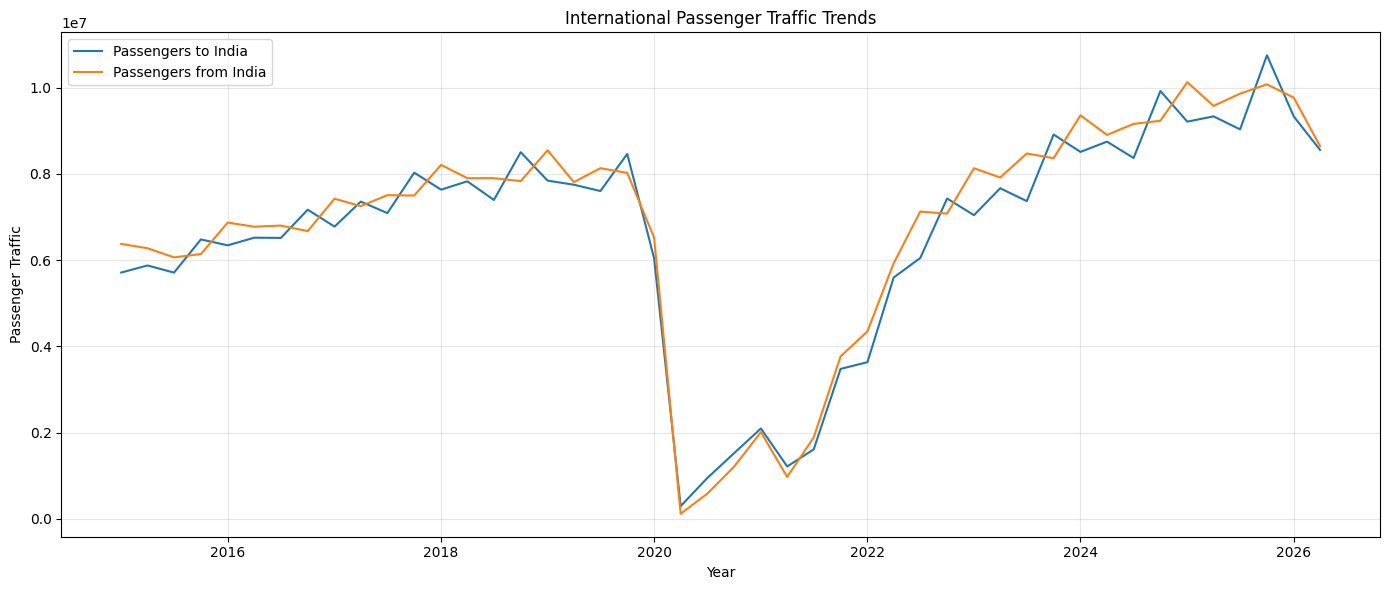

In [19]:
# Cell 8: Visualize Passenger Traffic

plt.figure(figsize=(14, 6))

plt.plot(
    quarterly_df.index,
    quarterly_df["PaxToIndia"],
    label="Passengers to India"
)

plt.plot(
    quarterly_df.index,
    quarterly_df["PaxFromIndia"],
    label="Passengers from India"
)

plt.title("International Passenger Traffic Trends")
plt.xlabel("Year")
plt.ylabel("Passenger Traffic")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

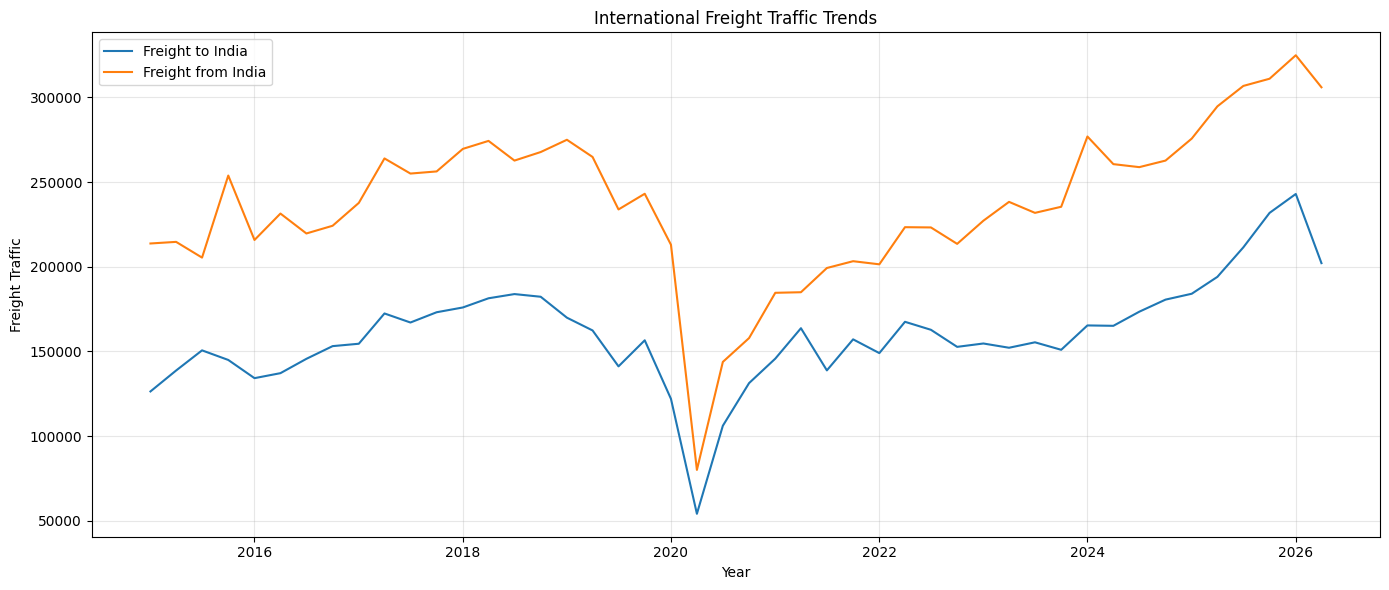

In [21]:
# Cell 9: International Freight Traffic Trends

plt.figure(figsize=(14, 6))

plt.plot(
    quarterly_df.index,
    quarterly_df["FreightToIndia"],
    label="Freight to India"
)

plt.plot(
    quarterly_df.index,
    quarterly_df["FreightFromIndia"],
    label="Freight from India"
)

plt.title("International Freight Traffic Trends")
plt.xlabel("Year")
plt.ylabel("Freight Traffic")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

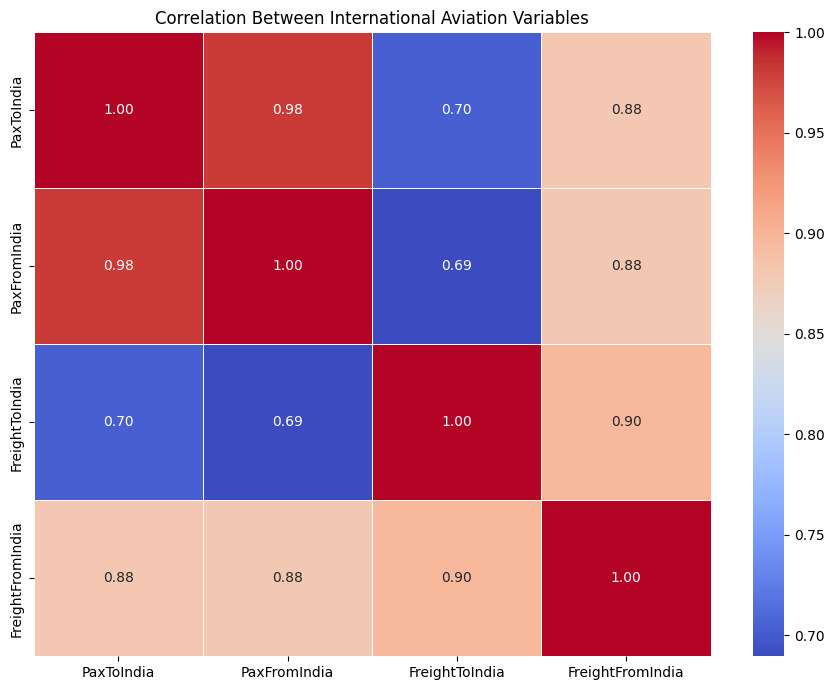

,PaxToIndia,PaxFromIndia,FreightToIndia,FreightFromIndia
PaxToIndia,1.000000,0.980888,0.703640,0.880909
PaxFromIndia,0.980888,1.000000,0.689646,0.878824
FreightToIndia,0.703640,0.689646,1.000000,0.895946
FreightFromIndia,0.880909,0.878824,0.895946,1.000000


In [23]:
# Cell 10: Correlation Between Aviation Variables

correlation_matrix = quarterly_df.corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between International Aviation Variables")
plt.tight_layout()
plt.show()

display(correlation_matrix)

In [25]:
# Cell 11: Validate the Quarterly Dataset

print("Dataset dimensions:", quarterly_df.shape)

print("\nStart date:", quarterly_df.index.min())
print("End date:", quarterly_df.index.max())

print("\nMissing values:")
display(quarterly_df.isnull().sum())

print("\nZero values:")
display((quarterly_df == 0).sum())

print("\nFirst five quarters:")
display(quarterly_df.head())

print("\nLast five quarters:")
display(quarterly_df.tail())

Dataset dimensions: (46, 4)

Start date: 2015-01-01 00:00:00
End date: 2026-04-01 00:00:00

Missing values:


PaxToIndia          0
PaxFromIndia        0
FreightToIndia      0
FreightFromIndia    0
dtype: int64


Zero values:


PaxToIndia          0
PaxFromIndia        0
FreightToIndia      0
FreightFromIndia    0
dtype: int64


First five quarters:


,PaxToIndia,PaxFromIndia,FreightToIndia,FreightFromIndia
Date,,,,
2015-01-01,5712230,6376365,126381.57,213762.57
2015-04-01,5876964,6276379,138740.32,214713.97
2015-07-01,5711102,6064483,150640.95,205418.27
2015-10-01,6481344,6141729,144974.47,253880.63
2016-01-01,6343530,6871288,134226.09,215835.76



Last five quarters:


,PaxToIndia,PaxFromIndia,FreightToIndia,FreightFromIndia
Date,,,,
2025-04-01,9335219,9577379,194060.46,294758.44
2025-07-01,9033491,9862786,211487.94,306815.02
2025-10-01,10752640,10077951,231833.54,311065.48
2026-01-01,9332607,9767964,243001.60,324925.18
2026-04-01,8556723,8643417,202149.61,306016.27


In [27]:
# Cell 12: Prepare Data for Forecasting

model_df = quarterly_df[
    [
        "PaxToIndia",
        "PaxFromIndia",
        "FreightToIndia",
        "FreightFromIndia"
    ]
].copy()

model_df = model_df.sort_index()

# Replace infinite values, if any
model_df = model_df.replace([np.inf, -np.inf], np.nan)

# Remove rows with missing values
model_df = model_df.dropna()

print("Model dataset shape:", model_df.shape)

display(model_df.head())

Model dataset shape: (46, 4)


,PaxToIndia,PaxFromIndia,FreightToIndia,FreightFromIndia
Date,,,,
2015-01-01,5712230,6376365,126381.57,213762.57
2015-04-01,5876964,6276379,138740.32,214713.97
2015-07-01,5711102,6064483,150640.95,205418.27
2015-10-01,6481344,6141729,144974.47,253880.63
2016-01-01,6343530,6871288,134226.09,215835.76


In [29]:
# Cell 13: Chronological Train/Test Split

split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("\nTraining period:")
print(train_df.index.min(), "to", train_df.index.max())

print("\nTesting period:")
print(test_df.index.min(), "to", test_df.index.max())

Training observations: 36
Testing observations: 10

Training period:
2015-01-01 00:00:00 to 2023-10-01 00:00:00

Testing period:
2024-01-01 00:00:00 to 2026-04-01 00:00:00


In [31]:
# Cell 14: Train SARIMAX Model

from statsmodels.tsa.statespace.sarimax import SARIMAX

target_column = "PaxToIndia"

feature_columns = [
    "PaxFromIndia",
    "FreightToIndia",
    "FreightFromIndia"
]

y_train = train_df[target_column]
y_test = test_df[target_column]

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

sarimax_model = SARIMAX(
    endog=y_train,
    exog=X_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 0, 4),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_results = sarimax_model.fit(disp=False)

print(sarimax_results.summary())

C:\Users\subas\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\subas\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                         PaxToIndia   No. Observations:                   36
Model:             SARIMAX(1, 1, 1)x(1, 1, [], 4)   Log Likelihood                -366.516
Date:                            Thu, 22 Oct 2026   AIC                            747.032
Time:                                    00:03:55   BIC                            755.839
Sample:                                01-01-2015   HQIC                           749.568
                                     - 10-01-2023                                         
Covariance Type:                              opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
PaxFromIndia         0.9344      0.119      7.843      0.000       0.701       1.168
FreightToIndia   

In [33]:
# Cell 15: Generate Test-Period Forecasts

forecast_result = sarimax_results.get_forecast(
    steps=len(test_df),
    exog=X_test
)

predictions = forecast_result.predicted_mean

predictions.index = test_df.index

print("Predictions generated successfully!")

display(
    pd.DataFrame({
        "Actual": y_test,
        "Predicted": predictions
    }).head(10)
)

Predictions generated successfully!


,Actual,Predicted
Date,,
2024-01-01,8510818,8.233406e+06
2024-04-01,8749019,8.940805e+06
2024-07-01,8369638,8.265769e+06
2024-10-01,9923696,1.014458e+07
2025-01-01,9212963,9.374020e+06
2025-04-01,9335219,9.932519e+06
2025-07-01,9033491,9.267112e+06
2025-10-01,10752640,1.139623e+07
2026-01-01,9332607,9.545544e+06


In [35]:
# Cell 16: Evaluate Forecast Performance

mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

# Avoid division by zero when calculating MAPE
nonzero_mask = y_test != 0

if nonzero_mask.any():
    mape = np.mean(
        np.abs(
            (
                y_test[nonzero_mask]
                - predictions[nonzero_mask]
            )
            / y_test[nonzero_mask]
        )
    ) * 100
else:
    mape = np.nan

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"MAPE: {mape:.2f}%")

MAE:  344,677.68
RMSE: 414,377.56
MAPE: 3.73%


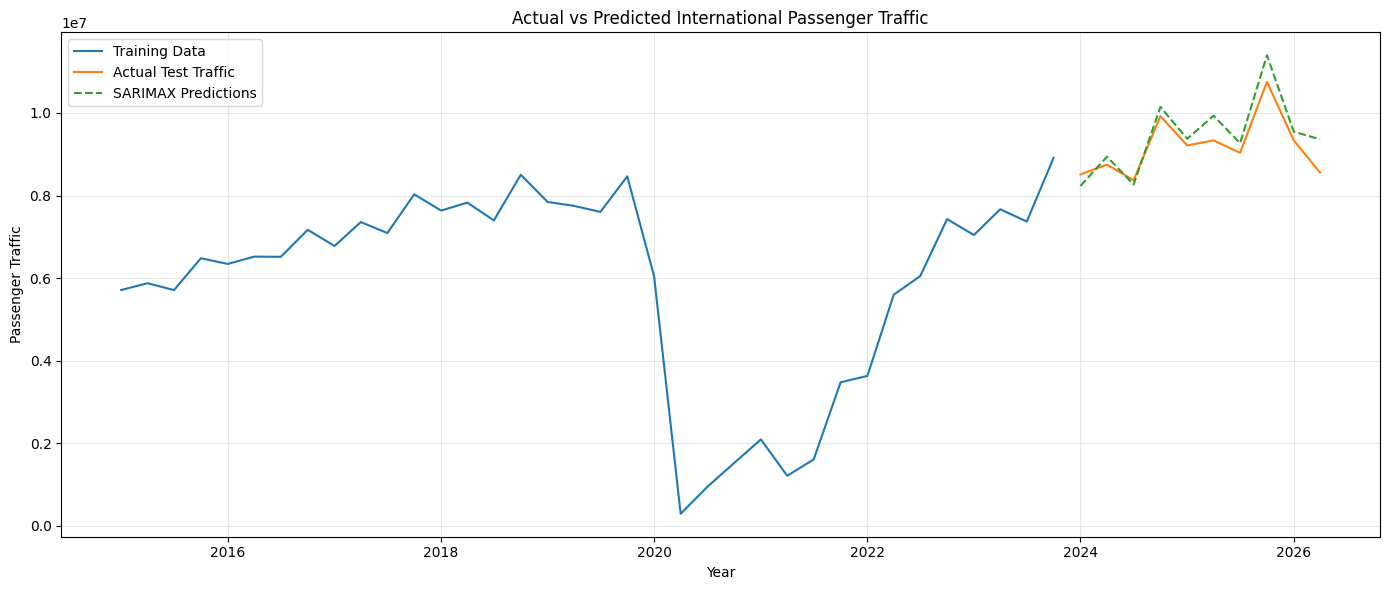

In [37]:
# Cell 17: Actual vs Predicted Passenger Traffic

plt.figure(figsize=(14, 6))

plt.plot(
    y_train.index,
    y_train,
    label="Training Data"
)

plt.plot(
    y_test.index,
    y_test,
    label="Actual Test Traffic"
)

plt.plot(
    predictions.index,
    predictions,
    label="SARIMAX Predictions",
    linestyle="--"
)

plt.title("Actual vs Predicted International Passenger Traffic")
plt.xlabel("Year")
plt.ylabel("Passenger Traffic")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
# Cell 18: Seasonal Naive Baseline Forecast

seasonal_period = 4

baseline_predictions = []

for i in range(len(test_df)):
    if i < seasonal_period:
        # Use the corresponding quarter from the training data
        prediction = train_df[target_column].iloc[
            -(seasonal_period - i)
        ]
    else:
        # Use the actual value from four quarters earlier
        prediction = test_df[target_column].iloc[
            i - seasonal_period
        ]

    baseline_predictions.append(prediction)

baseline_predictions = pd.Series(
    baseline_predictions,
    index=test_df.index,
    name="Seasonal Naive"
)

print("Seasonal baseline predictions generated!")

display(pd.DataFrame({
    "Actual": y_test,
    "SARIMAX": predictions,
    "Seasonal_Naive": baseline_predictions
}).head(10))

Seasonal baseline predictions generated!


,Actual,SARIMAX,Seasonal_Naive
Date,,,
2024-01-01,8510818,8.233406e+06,7042996
2024-04-01,8749019,8.940805e+06,7667677
2024-07-01,8369638,8.265769e+06,7369804
2024-10-01,9923696,1.014458e+07,8913959
2025-01-01,9212963,9.374020e+06,8510818
2025-04-01,9335219,9.932519e+06,8749019
2025-07-01,9033491,9.267112e+06,8369638
2025-10-01,10752640,1.139623e+07,9923696
2026-01-01,9332607,9.545544e+06,9212963


In [41]:
# Cell 19: Compare Forecasting Models

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    nonzero = actual != 0

    if nonzero.any():
        mape = np.mean(
            np.abs(
                (actual[nonzero] - predicted[nonzero])
                / actual[nonzero]
            )
        ) * 100
    else:
        mape = np.nan

    return mae, rmse, mape


sarimax_metrics = calculate_metrics(
    y_test, predictions
)

baseline_metrics = calculate_metrics(
    y_test, baseline_predictions
)

comparison_df = pd.DataFrame(
    [
        {
            "Model": "SARIMAX",
            "MAE": sarimax_metrics[0],
            "RMSE": sarimax_metrics[1],
            "MAPE (%)": sarimax_metrics[2]
        },
        {
            "Model": "Seasonal Naive",
            "MAE": baseline_metrics[0],
            "RMSE": baseline_metrics[1],
            "MAPE (%)": baseline_metrics[2]
        }
    ]
)

display(comparison_df.round(2))

,Model,MAE,RMSE,MAPE (%)
0,SARIMAX,344677.68,414377.56,3.73
1,Seasonal Naive,823801.70,890387.36,9.11


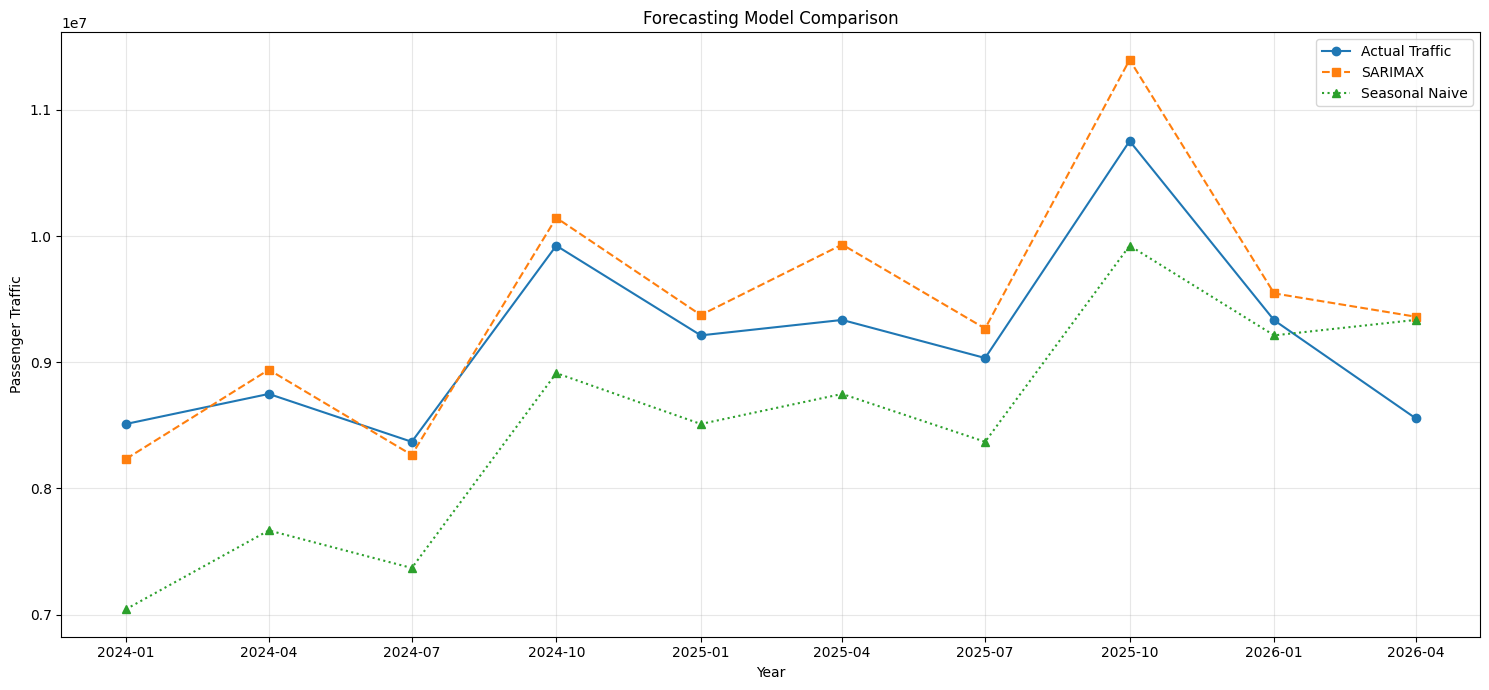

In [43]:
# Cell 20: Compare Actual and Predicted Passenger Traffic

plt.figure(figsize=(15, 7))

plt.plot(
    y_test.index,
    y_test,
    label="Actual Traffic",
    marker="o"
)

plt.plot(
    predictions.index,
    predictions,
    label="SARIMAX",
    linestyle="--",
    marker="s"
)

plt.plot(
    baseline_predictions.index,
    baseline_predictions,
    label="Seasonal Naive",
    linestyle=":",
    marker="^"
)

plt.title("Forecasting Model Comparison")
plt.xlabel("Year")
plt.ylabel("Passenger Traffic")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
# Cell 21: Train a Seasonal ARIMA Model

from statsmodels.tsa.statespace.sarimax import SARIMAX

passenger_series = quarterly_df["PaxToIndia"].sort_index()

# Keep only observations available before the test period
passenger_train = passenger_series.loc[train_df.index.min():train_df.index.max()]

future_model = SARIMAX(
    passenger_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 0, 4),
    enforce_stationarity=False,
    enforce_invertibility=False
)

future_results = future_model.fit(disp=False)

print(future_results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         PaxToIndia   No. Observations:                   36
Model:             SARIMAX(1, 1, 1)x(1, 1, [], 4)   Log Likelihood                -409.346
Date:                            Thu, 22 Oct 2026   AIC                            826.692
Time:                                    00:06:50   BIC                            831.725
Sample:                                01-01-2015   HQIC                           828.141
                                     - 10-01-2023                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3815      2.246      0.170      0.865      -4.021       4.784
ma.L1         -0.1773      2.374   

C:\Users\subas\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\subas\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


In [47]:
# Cell 22: Forecast the Next Four Quarters

forecast_steps = 4

future_forecast = future_results.get_forecast(
    steps=forecast_steps
)

forecast_mean = future_forecast.predicted_mean

forecast_interval = future_forecast.conf_int()

future_dates = pd.date_range(
    start=passenger_train.index[-1] + pd.offsets.QuarterBegin(startingMonth=1),
    periods=forecast_steps,
    freq="QS"
)

forecast_mean.index = future_dates
forecast_interval.index = future_dates

future_forecast_df = pd.DataFrame({
    "Forecast_Passengers": forecast_mean,
    "Lower_95%": forecast_interval.iloc[:, 0],
    "Upper_95%": forecast_interval.iloc[:, 1]
})

display(future_forecast_df.round(2))

,Forecast_Passengers,Lower_95%,Upper_95%
2024-01-01,8654515.07,5315257.02,11993773.12
2024-04-01,9646982.77,4420199.56,14873765.99
2024-07-01,9556714.09,2800457.95,16312970.23
2024-10-01,11053190.65,3001234.49,19105146.82


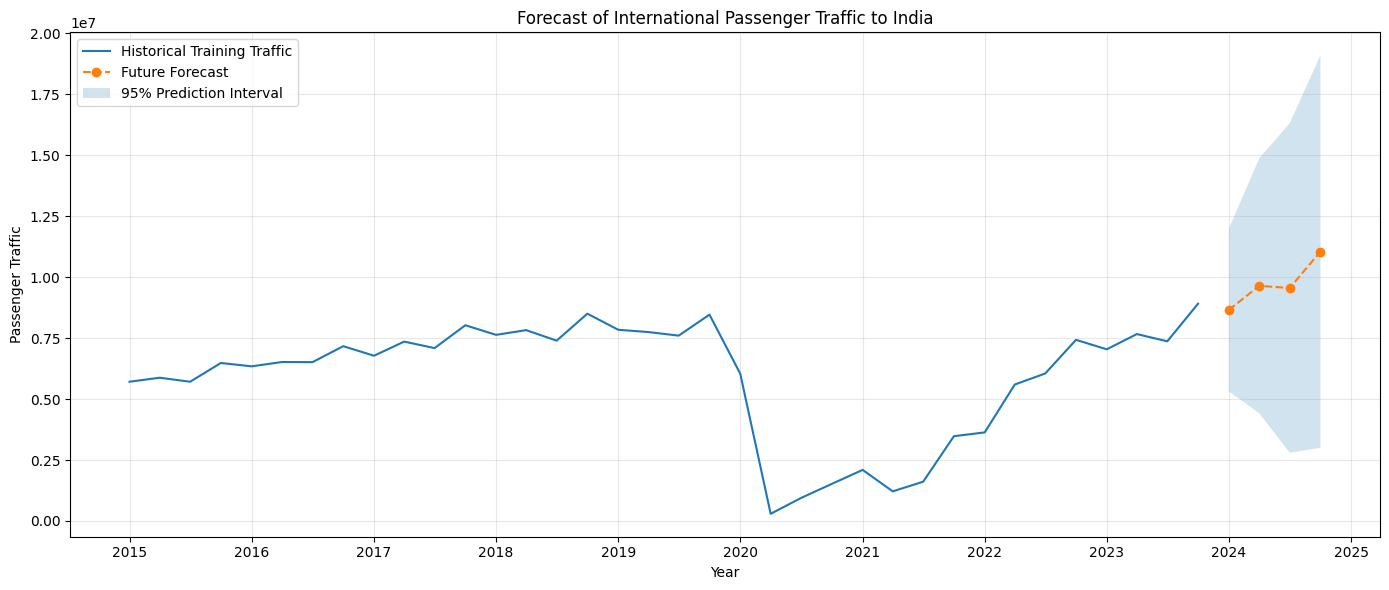

In [49]:
# Cell 23: Plot Future Passenger Traffic Forecast

plt.figure(figsize=(14, 6))

plt.plot(
    passenger_train.index,
    passenger_train,
    label="Historical Training Traffic"
)

plt.plot(
    future_forecast_df.index,
    future_forecast_df["Forecast_Passengers"],
    label="Future Forecast",
    marker="o",
    linestyle="--"
)

plt.fill_between(
    future_forecast_df.index,
    future_forecast_df["Lower_95%"],
    future_forecast_df["Upper_95%"],
    alpha=0.2,
    label="95% Prediction Interval"
)

plt.title("Forecast of International Passenger Traffic to India")
plt.xlabel("Year")
plt.ylabel("Passenger Traffic")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [51]:
# Cell 24: Save Model Comparison Results

OUTPUT_DIR = r"E:\india-aviation-traffic-main\outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

comparison_path = os.path.join(
    OUTPUT_DIR,
    "model_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("Model comparison saved to:")
print(comparison_path)

Model comparison saved to:
E:\india-aviation-traffic-main\outputs\model_comparison.csv


In [53]:
# Cell 25: Save Future Forecast Results

forecast_path = os.path.join(
    OUTPUT_DIR,
    "future_passenger_forecast.csv"
)

future_forecast_df.to_csv(
    forecast_path,
    index_label="Date"
)

print("Future forecast saved to:")
print(forecast_path)

Future forecast saved to:
E:\india-aviation-traffic-main\outputs\future_passenger_forecast.csv


In [55]:
# Cell 26: Verify Exported Results

OUTPUT_DIR = r"E:\india-aviation-traffic-main\outputs"

print("MODEL COMPARISON RESULTS")
comparison_check = pd.read_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv")
)
display(comparison_check)

print("\nFUTURE PASSENGER FORECAST")
forecast_check = pd.read_csv(
    os.path.join(OUTPUT_DIR, "future_passenger_forecast.csv")
)
display(forecast_check)

print("\nAll exported results loaded successfully!")

MODEL COMPARISON RESULTS


,Model,MAE,RMSE,MAPE (%)
0,SARIMAX,344677.679213,414377.558727,3.731806
1,Seasonal Naive,823801.700000,890387.359069,9.106589



FUTURE PASSENGER FORECAST


,Date,Forecast_Passengers,Lower_95%,Upper_95%
0,2024-01-01,8.654515e+06,5.315257e+06,1.199377e+07
1,2024-04-01,9.646983e+06,4.420200e+06,1.487377e+07
2,2024-07-01,9.556714e+06,2.800458e+06,1.631297e+07
3,2024-10-01,1.105319e+07,3.001234e+06,1.910515e+07



All exported results loaded successfully!


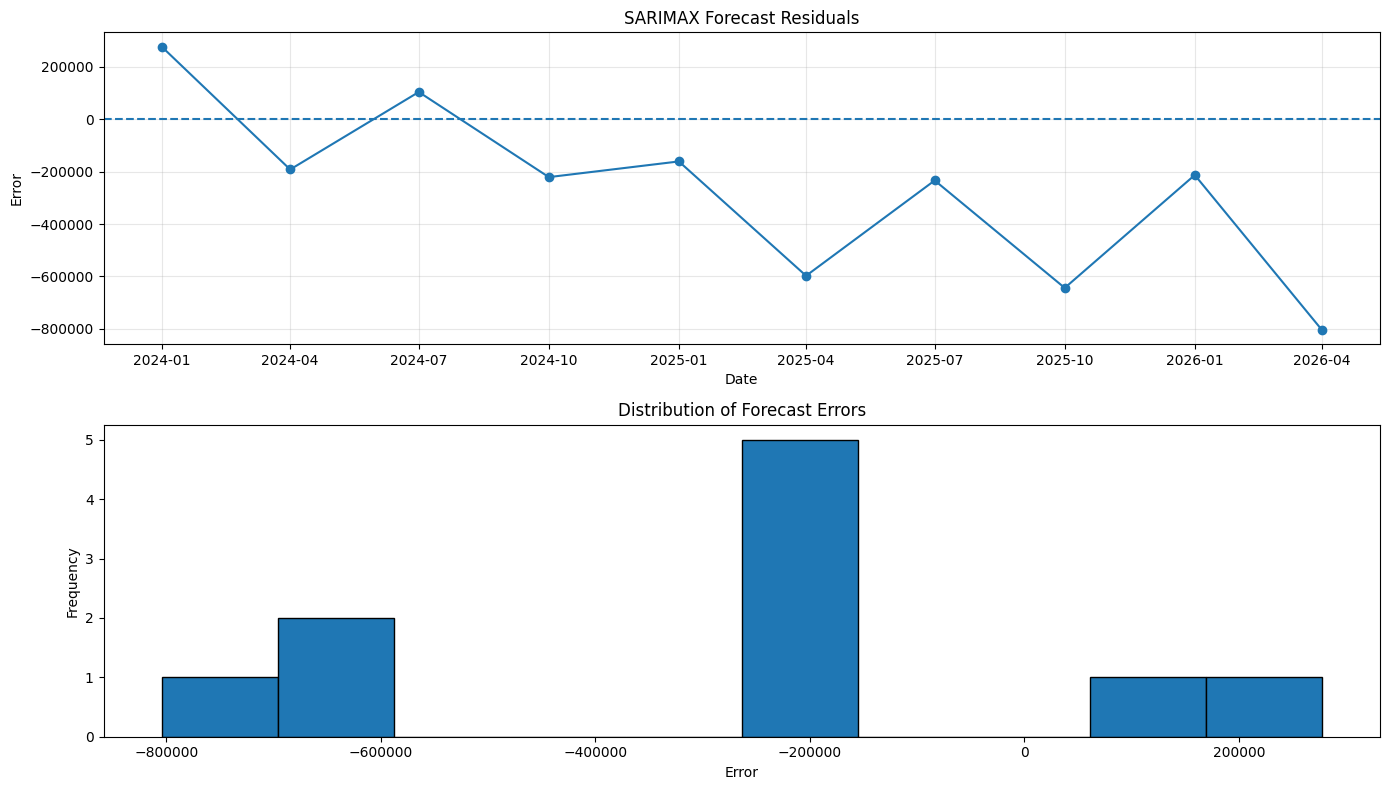

Mean residual: -268421.5
Residual standard deviation: 332763.94


In [57]:
# Cell 27: SARIMAX Residual Analysis

residuals = y_test - predictions

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(residuals.index, residuals, marker="o")
axes[0].axhline(0, linestyle="--")
axes[0].set_title("SARIMAX Forecast Residuals")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Error")
axes[0].grid(True, alpha=0.3)

axes[1].hist(residuals, bins=10, edgecolor="black")
axes[1].set_title("Distribution of Forecast Errors")
axes[1].set_xlabel("Error")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 2))
print("Residual standard deviation:", round(residuals.std(), 2))

In [59]:
# Cell 28: Fair Four-Quarter Forecast Comparison

from statsmodels.tsa.statespace.sarimax import SARIMAX

# Use the same training period for both models
train_series = train_df["PaxToIndia"].copy()
actual_four = test_df["PaxToIndia"].iloc[:4].copy()

# Seasonal-naive forecast: repeat the last four observed quarters
seasonal_forecast = train_series.iloc[-4:].copy()
seasonal_forecast.index = actual_four.index

# SARIMAX forecast over the same four-quarter horizon
comparison_model = SARIMAX(
    train_series,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 0, 4),
    enforce_stationarity=False,
    enforce_invertibility=False
)

comparison_fit = comparison_model.fit(disp=False)

sarimax_four = comparison_fit.get_forecast(
    steps=4
).predicted_mean

sarimax_four.index = actual_four.index

# Compare errors over the same horizon
fair_comparison = pd.DataFrame({
    "Actual": actual_four,
    "SARIMAX": sarimax_four,
    "Seasonal_Naive": seasonal_forecast
})

display(fair_comparison.round(2))

fair_metrics = []

for name in ["SARIMAX", "Seasonal_Naive"]:
    mae = mean_absolute_error(
        fair_comparison["Actual"],
        fair_comparison[name]
    )

    rmse = np.sqrt(
        mean_squared_error(
            fair_comparison["Actual"],
            fair_comparison[name]
        )
    )

    fair_metrics.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

fair_metrics_df = pd.DataFrame(fair_metrics)
display(fair_metrics_df.round(2))

C:\Users\subas\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\subas\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


,Actual,SARIMAX,Seasonal_Naive
Date,,,
2024-01-01,8510818,8654515.07,7042996
2024-04-01,8749019,9646982.77,7667677
2024-07-01,8369638,9556714.09,7369804
2024-10-01,9923696,11053190.65,8913959


,Model,MAE,RMSE
0,SARIMAX,839557.90,937002.61
1,Seasonal_Naive,1139683.75,1155750.71


In [61]:
# Cell 29: Save Final Model Comparison

fair_metrics_path = os.path.join(
    OUTPUT_DIR,
    "final_model_comparison.csv"
)

fair_metrics_df.to_csv(
    fair_metrics_path,
    index=False
)

print("Final model comparison saved:")
print(fair_metrics_path)

Final model comparison saved:
E:\india-aviation-traffic-main\outputs\final_model_comparison.csv


In [63]:
# Cell 30: Save Quarterly Aviation Traffic Dataset

import os
import pandas as pd

# Define the output folder
OUTPUT_DIR = r"E:\india-aviation-traffic-main\outputs"

# Create the folder if it does not exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Verify that quarterly_df exists
if "quarterly_df" not in globals():
    raise NameError(
        "quarterly_df is not available. "
        "Please execute Cell 7 (quarterly aggregation) first."
    )

# Define the output file path
processed_path = os.path.join(
    OUTPUT_DIR,
    "quarterly_aviation_traffic.csv"
)

# Save the processed dataset
quarterly_df.to_csv(
    processed_path,
    index_label="Date"
)

print("Quarterly aviation dataset saved successfully!")
print("File location:", processed_path)
print("Number of rows:", len(quarterly_df))
print("Number of columns:", len(quarterly_df.columns))

display(quarterly_df.head())

Quarterly aviation dataset saved successfully!
File location: E:\india-aviation-traffic-main\outputs\quarterly_aviation_traffic.csv
Number of rows: 46
Number of columns: 4


,PaxToIndia,PaxFromIndia,FreightToIndia,FreightFromIndia
Date,,,,
2015-01-01,5712230,6376365,126381.57,213762.57
2015-04-01,5876964,6276379,138740.32,214713.97
2015-07-01,5711102,6064483,150640.95,205418.27
2015-10-01,6481344,6141729,144974.47,253880.63
2016-01-01,6343530,6871288,134226.09,215835.76


In [65]:
# Cell 31: Verify the Saved CSV File

file_path = (
    r"E:\india-aviation-traffic-main\outputs"
    r"\quarterly_aviation_traffic.csv"
)

if os.path.exists(file_path):
    print("SUCCESS: File exists!")
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")

    saved_df = pd.read_csv(file_path)

    print("\nSaved dataset preview:")
    display(saved_df.head(10))
else:
    print("File not found. Please check the output path.")

SUCCESS: File exists!
File size: 2.27 KB

Saved dataset preview:


,Date,PaxToIndia,PaxFromIndia,FreightToIndia,FreightFromIndia
0,2015-01-01,5712230,6376365,126381.57,213762.57
1,2015-04-01,5876964,6276379,138740.32,214713.97
2,2015-07-01,5711102,6064483,150640.95,205418.27
3,2015-10-01,6481344,6141729,144974.47,253880.63
4,2016-01-01,6343530,6871288,134226.09,215835.76
5,2016-04-01,6521248,6775745,137173.95,231436.68
6,2016-07-01,6515859,6802518,145634.17,219675.55
7,2016-10-01,7170031,6672921,153138.67,224225.61
8,2017-01-01,6778304,7424671,154550.51,237738.80
9,2017-04-01,7357808,7252972,172434.22,263992.58


In [67]:
# Cell 31: Final Project Results Summary

print("=" * 60)
print("CIVIL AVIATION FORECASTING - PROJECT SUMMARY")
print("=" * 60)

print("\n1. DATASET INFORMATION")
print("Total quarterly observations:", len(quarterly_df))
print("Start date:", quarterly_df.index.min().date())
print("End date:", quarterly_df.index.max().date())
print("Variables:", list(quarterly_df.columns))

print("\n2. FORECASTING MODEL")
print("Model: SARIMAX")
print("Target variable: PaxToIndia")
print("Forecast frequency: Quarterly")

print("\n3. MODEL PERFORMANCE")
display(fair_metrics_df.round(2))

print("\n4. FUTURE FORECAST")
display(future_forecast_df.round(2))

print("\n5. OUTPUT FILES")
for file in sorted(os.listdir(OUTPUT_DIR)):
    print("-", file)

print("\nProject results summary generated successfully!")

CIVIL AVIATION FORECASTING - PROJECT SUMMARY

1. DATASET INFORMATION
Total quarterly observations: 46
Start date: 2015-01-01
End date: 2026-04-01
Variables: ['PaxToIndia', 'PaxFromIndia', 'FreightToIndia', 'FreightFromIndia']

2. FORECASTING MODEL
Model: SARIMAX
Target variable: PaxToIndia
Forecast frequency: Quarterly

3. MODEL PERFORMANCE


,Model,MAE,RMSE
0,SARIMAX,839557.90,937002.61
1,Seasonal_Naive,1139683.75,1155750.71



4. FUTURE FORECAST


,Forecast_Passengers,Lower_95%,Upper_95%
2024-01-01,8654515.07,5315257.02,11993773.12
2024-04-01,9646982.77,4420199.56,14873765.99
2024-07-01,9556714.09,2800457.95,16312970.23
2024-10-01,11053190.65,3001234.49,19105146.82



5. OUTPUT FILES
- final_model_comparison.csv
- future_passenger_forecast.csv
- model_comparison.csv
- quarterly_aviation_traffic.csv

Project results summary generated successfully!


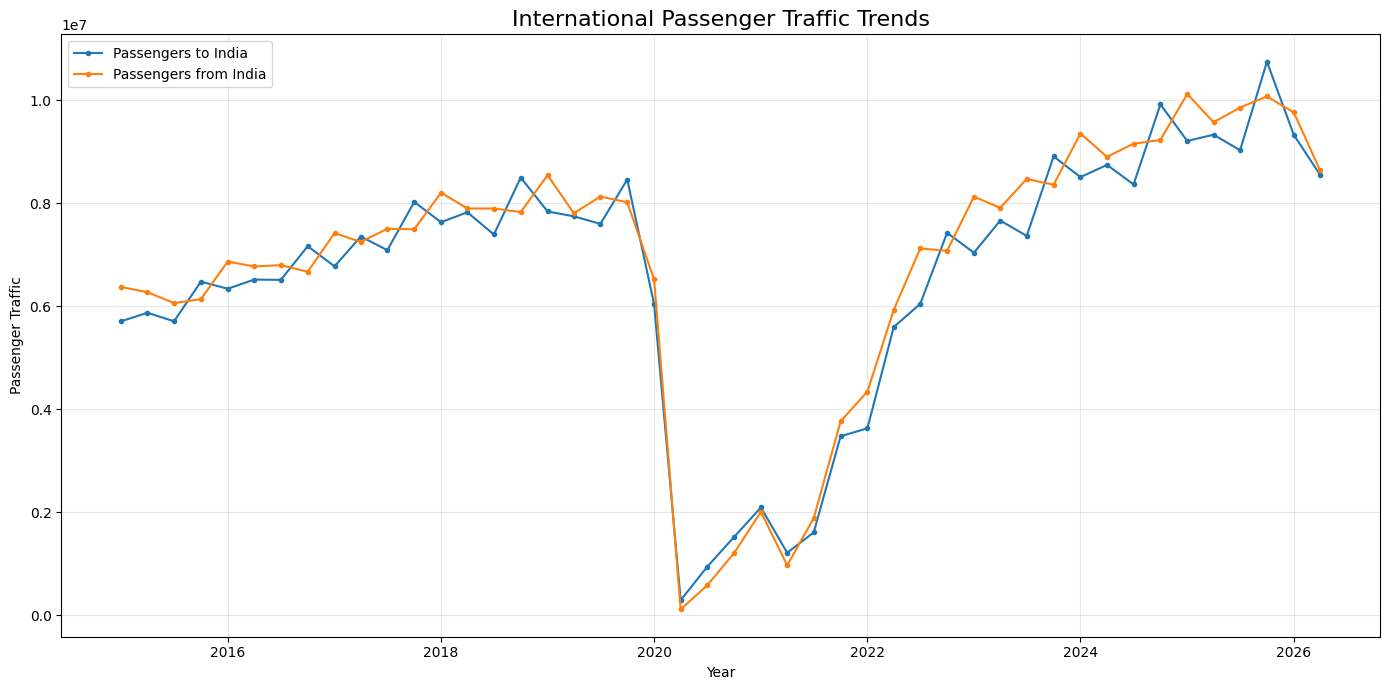

Graph saved to: E:\india-aviation-traffic-main\outputs\passenger_traffic_trends.png


In [69]:
# Cell 32: Save Passenger Traffic Trend Graph

import os
import matplotlib.pyplot as plt

OUTPUT_DIR = r"E:\india-aviation-traffic-main\outputs"

plt.figure(figsize=(14, 7))

plt.plot(
    quarterly_df.index,
    quarterly_df["PaxToIndia"],
    label="Passengers to India",
    marker="o",
    markersize=3
)

plt.plot(
    quarterly_df.index,
    quarterly_df["PaxFromIndia"],
    label="Passengers from India",
    marker="o",
    markersize=3
)

plt.title(
    "International Passenger Traffic Trends",
    fontsize=16
)

plt.xlabel("Year")
plt.ylabel("Passenger Traffic")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

graph_path = os.path.join(
    OUTPUT_DIR,
    "passenger_traffic_trends.png"
)

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved to:", graph_path)

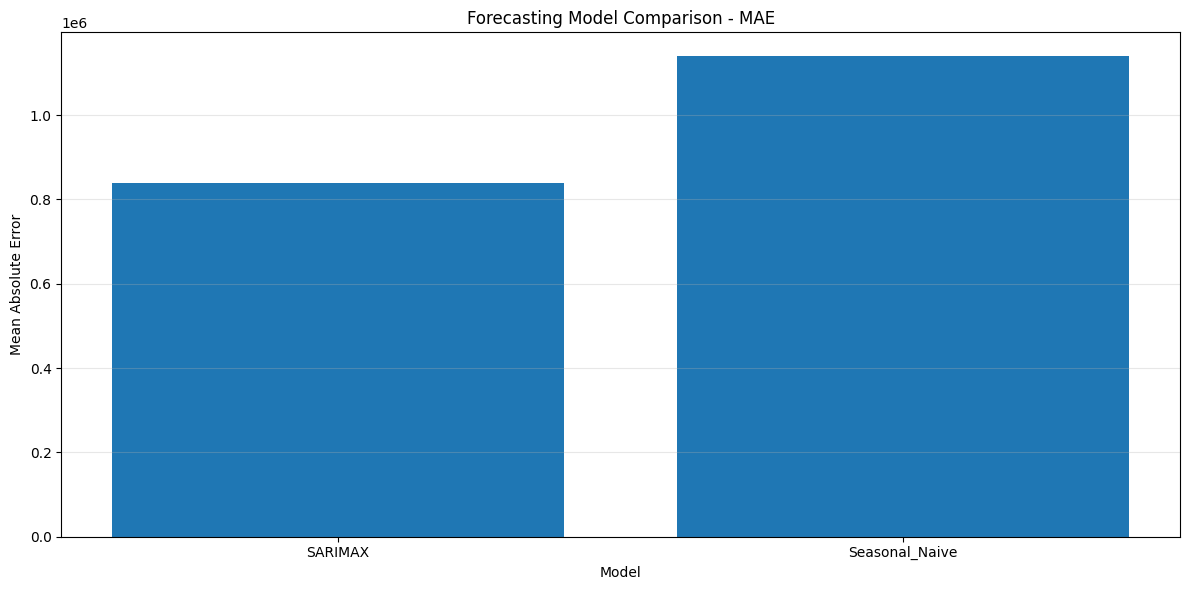

Model comparison graph saved to:
E:\india-aviation-traffic-main\outputs\model_comparison.png


In [71]:
# Cell 33: Save Model Comparison Graph

plt.figure(figsize=(12, 6))

plt.bar(
    fair_metrics_df["Model"],
    fair_metrics_df["MAE"]
)

plt.title("Forecasting Model Comparison - MAE")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

comparison_graph_path = os.path.join(
    OUTPUT_DIR,
    "model_comparison.png"
)

plt.savefig(
    comparison_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison graph saved to:")
print(comparison_graph_path)

In [73]:
# Cell 35: Final Project Validation

import os
import pandas as pd

OUTPUT_DIR = r"E:\india-aviation-traffic-main\outputs"

required_files = [
    "quarterly_aviation_traffic.csv",
    "model_comparison.csv",
    "final_model_comparison.csv",
    "future_passenger_forecast.csv",
    "passenger_traffic_trends.png",
    "model_comparison.png"
]

print("FINAL PROJECT OUTPUT VALIDATION")
print("-" * 45)

for filename in required_files:
    path = os.path.join(OUTPUT_DIR, filename)

    if os.path.exists(path):
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")

print("\nValidation completed.")

FINAL PROJECT OUTPUT VALIDATION
---------------------------------------------
FOUND: quarterly_aviation_traffic.csv
FOUND: model_comparison.csv
FOUND: final_model_comparison.csv
FOUND: future_passenger_forecast.csv
FOUND: passenger_traffic_trends.png
FOUND: model_comparison.png

Validation completed.
